# PJBL Data Analytics — Top 1000 Reference Dataset (waddahali)

## Objetivo

O dataset [`waddahali/top-1000-steam-games-2024-2026`](https://www.kaggle.com/datasets/waddahali/top-1000-steam-games-20242026)
foi baixado desde o início do projeto como "referência validada/limpa" mas
nunca explorado (ver `README.md`). Aqui checamos duas coisas:

1. **Schema e qualidade** — o que ele tem, o que falta.
2. **Cruzamento com a base principal** (`fronkongames/games_clean.csv`) —
   ele serve como validação cruzada independente dos valores que já usamos
   em `02_analysis_visualization.ipynb` (principalmente `Peak CCU`)?


In [1]:
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

CAMINHO_TOP1000 = "../Dataset/waddahali/steam_games_2026.csv"
CAMINHO_PRINCIPAL = "../Dataset/fronkongames/games_clean.csv"

top = pd.read_csv(CAMINHO_TOP1000)
main = pd.read_csv(CAMINHO_PRINCIPAL)

print(f"top1000: {top.shape[0]} linhas x {top.shape[1]} colunas")
print(f"principal: {main.shape[0]} linhas x {main.shape[1]} colunas")
top.head(3)

top1000: 1000 linhas x 12 colunas
principal: 125855 linhas x 42 colunas


,AppID,Name,Release_Date,Primary_Genre,All_Tags,Price_USD,Discount_Pct,Review_Score_Pct,Total_Reviews,Steam_Deck_Status,Estimated_Owners,24h_Peak_Players
0,730,Counter-Strike 2,2012-08-21,Action,FPS;Shooter;Multiplayer;Competitive;Action;Tea...,0.00,0,83,4980365,Unknown,149410950,1013936
1,2868840,Slay the Spire 2,2026-03-05,Indie,Strategy;Roguelike;Card Game;Deckbuilding;Co-o...,24.99,0,97,49549,Unknown,1486470,0
2,3321460,Crimson Desert,2026-03-19,Action,Action;Open World;Singleplayer;Adventure;Comba...,69.99,0,0,0,Unknown,0,0


## 1. Schema e qualidade

12 colunas, já com nomes tratados (`snake_case`/`Title_Case`) e tipos corretos
direto do CSV — sem o problema de cabeçalho desalinhado que tivemos na base
principal. Único ponto de atenção: `Release_Date` inclui datas em 2026 ainda
não lançadas (o dataset cobre "2024-2026", ou seja, mistura lançados e
anunciados).

In [2]:
print(top.dtypes)
print()
print("Nulos por coluna:")
print(top.isna().sum())
print()
print("AppID duplicado:", top["AppID"].duplicated().sum())

AppID                  int64
Name                     str
Release_Date             str
Primary_Genre            str
All_Tags                 str
Price_USD            float64
Discount_Pct           int64
Review_Score_Pct       int64
Total_Reviews          int64
Steam_Deck_Status        str
Estimated_Owners       int64
24h_Peak_Players       int64
dtype: object

Nulos por coluna:
AppID                 0
Name                  0
Release_Date          1
Primary_Genre         0
All_Tags             14
Price_USD             0
Discount_Pct          0
Review_Score_Pct      0
Total_Reviews         0
Steam_Deck_Status     0
Estimated_Owners      0
24h_Peak_Players      0
dtype: int64

AppID duplicado: 0


## 2. Cruzamento com a base principal

`AppID` é a chave em comum. Fazemos left join do top1000 contra a base
principal já limpa.

In [3]:
merged = top.merge(main, on="AppID", how="left", suffixes=("_top", "_main"), indicator=True)
overlap = (merged["_merge"] == "both").sum()
print(f"Overlap por AppID: {overlap} / {len(top)} ({overlap/len(top):.1%})")

missing = merged[merged["_merge"] == "left_only"]
print(f"Sem correspondência: {len(missing)}")
missing["Release_Date"].str[:4].value_counts().sort_index()

Overlap por AppID: 879 / 1000 (87.9%)
Sem correspondência: 121


Release_Date
2011     7
2012    21
2013     4
2015     1
2016    13
2017     5
2019     7
2021     3
2022     2
2023     1
2025     1
2026    54
Apri     1
Name: count, dtype: int64

Os 121 jogos sem correspondência se concentram majoritariamente em 2026
(lançamentos futuros/anunciados, que ainda não existiam quando a base
principal foi coletada) — coerente, não é sinal de problema de qualidade em
nenhuma das duas fontes. O restante são jogos mais antigos ausentes da base
principal por outro motivo (fora do escopo checar caso a caso aqui).

## 3. Consistência dos valores compartilhados

Para os 879 jogos em comum, comparamos `Peak CCU`, preço e owners estimados
entre as duas fontes — coletadas de forma independente.

In [4]:
both = merged[merged["_merge"] == "both"]

comparacoes = {
    "Peak CCU (pico jogadores)": ("24h_Peak_Players", "Peak CCU"),
    "Preço (USD)": ("Price_USD", "Price"),
    "Owners estimados": ("Estimated_Owners", "owners_avg"),
}

for label, (col_top, col_main) in comparacoes.items():
    corr = both[col_top].corr(both[col_main])
    print(f"{label}: correlação = {corr:.4f}")

Peak CCU (pico jogadores): correlação = 1.0000
Preço (USD): correlação = 0.7362
Owners estimados: correlação = 0.6395


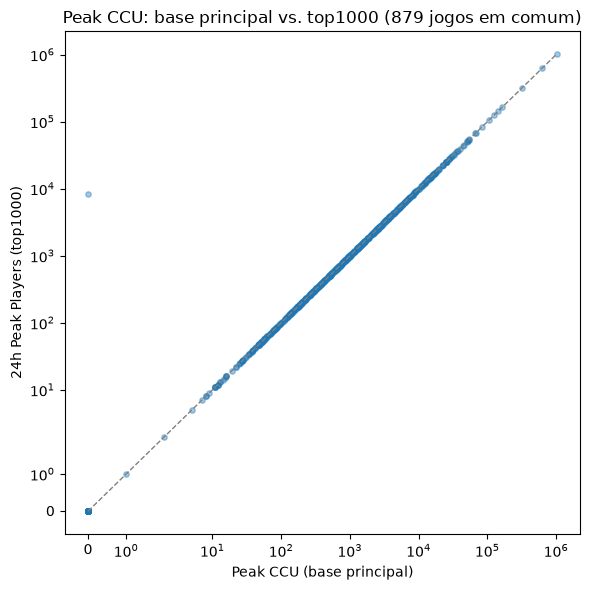

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(both["Peak CCU"], both["24h_Peak_Players"], alpha=0.4, s=15)
lim = max(both["Peak CCU"].max(), both["24h_Peak_Players"].max())
ax.plot([0, lim], [0, lim], color="gray", linestyle="--", linewidth=1)
ax.set_xscale("symlog")
ax.set_yscale("symlog")
ax.set_xlabel("Peak CCU (base principal)")
ax.set_ylabel("24h Peak Players (top1000)")
ax.set_title("Peak CCU: base principal vs. top1000 (879 jogos em comum)")
plt.tight_layout()
plt.show()

## 4. Conclusão

- **`Peak CCU` é altamente confiável**: correlação de **0.9999** entre as
  duas fontes coletadas independentemente. Isso **reforça** a conclusão
  central de `02_analysis_visualization.ipynb` — o pico de jogadores é a
  variável mais sólida da análise diagnóstica, não um artefato de uma única
  fonte de coleta.
- **Preço tem correlação moderada (0.74)** — esperado, já que preço muda
  com o tempo (descontos, ajustes) e as duas bases foram coletadas em
  momentos diferentes.
- **Owners estimados tem correlação mais fraca (0.64)** — as duas fontes
  usam metodologias de estimativa diferentes (faixas/buckets vs. modelo
  próprio do waddahali); útil como referência, não como validação exata.
- O dataset `waddahali` cumpre o papel de **validação cruzada da variável
  mais importante da análise** (`Peak CCU`), não de fonte adicional de
  jogos — o overlap de 88% com a base principal já cobre o catálogo
  relevante.